In [1]:
from qiskit.quantum_info import SparsePauliOp
from qiskit_algorithms import NumPyMinimumEigensolver

H2_op = SparsePauliOp.from_list(
    [
        ("II", -1.052373245772859),
        ("IZ", 0.39793742484318045),
        ("ZI", -0.39793742484318045),
        ("ZZ", -0.01128010425623538),
        ("XX", 0.18093119978423156),
    ]
)

numpy_solver = NumPyMinimumEigensolver()
result = numpy_solver.compute_minimum_eigenvalue(operator=H2_op)
ref_value = result.eigenvalue.real
print(f"Reference value: {ref_value:.5f}")

Reference value: -1.85728


In [2]:
from qiskit_ibm_runtime.fake_provider import FakeLimaV2
from qiskit.circuit.library import n_local
from qiskit import transpile

backend = FakeLimaV2()

ansatz = n_local(2, rotation_blocks="ry", entanglement_blocks="cz")

transpiled_ansatz = transpile(ansatz, backend=backend, optimization_level=3)

print("Transpilation complete for FakeLimaV2.")

Transpilation complete for FakeLimaV2.


In [3]:
from qiskit_aer.primitives import EstimatorV2 as AerEstimator

noisy_estimator = AerEstimator.from_backend(backend)
noisy_estimator.options.default_precision = 1e-2

In [4]:
from qiskit_algorithms.optimizers import SPSA
from qiskit_algorithms import VQE

counts = []
values = []
param_list = []

def store_intermediate_result(eval_count, parameters, mean, std):
    counts.append(eval_count)
    values.append(mean)
    param_list.append(parameters)

iterations = 125
spsa = SPSA(maxiter=iterations)

vqe = VQE(noisy_estimator, transpiled_ansatz, optimizer=spsa, callback=store_intermediate_result)

In [5]:
result_lima = vqe.compute_minimum_eigenvalue(operator=H2_op)

print(f"VQE on FakeLimaV2: {result_lima.eigenvalue.real:.5f}")
print(f"Delta from reference: {(result_lima.eigenvalue.real - ref_value):.5f}")

VQE on FakeLimaV2: -1.84289
Delta from reference: 0.01438


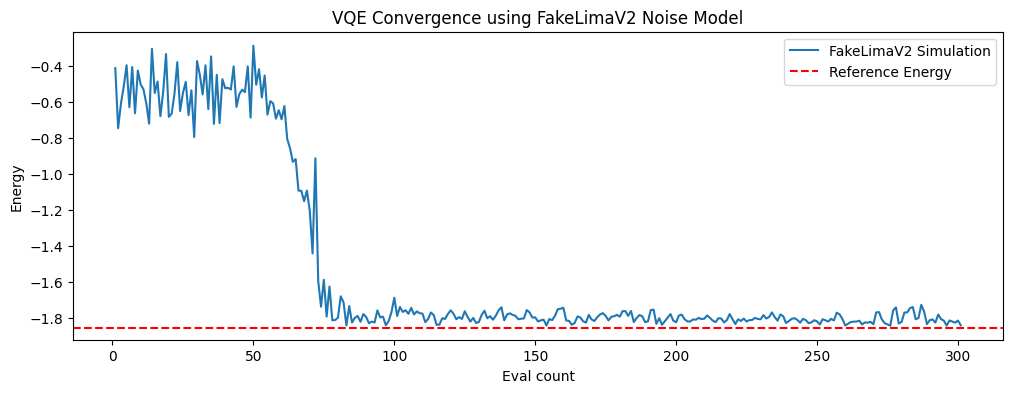

In [6]:
import pylab

pylab.rcParams["figure.figsize"] = (12, 4)
pylab.plot(counts, values, label="FakeLimaV2 Simulation")
pylab.axhline(y=ref_value, color='r', linestyle='--', label="Reference Energy")
pylab.xlabel("Eval count")
pylab.ylabel("Energy")
pylab.title("VQE Convergence using FakeLimaV2 Noise Model")
pylab.legend()
pylab.show()